# 1. Running simulations

Load an `.ode` file, change parameters and initial conditions, integrate, and get the data
browser back as a numpy array. No X11 window opens; XPP's terminal output goes to `m.log`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyxpp

## Load a model

In [2]:
m = pyxpp.load("../lecar.ode")
m

<pyxpp.Model lecar.ode: vars=['V', 'W'] aux=['CUR', 'ICA', 'IK', 'RATE'] pars=12>

In [3]:
print(m.vars)      # state variables
print(m.aux)       # aux quantities (also columns of the data)
print(m.pars)      # parameters, dict-like
print(m.ics)       # initial conditions, dict-like

['V', 'W']
['CUR', 'ICA', 'IK', 'RATE']
parameters(iapp=0, phi=0.333, v1=-0.01, v2=0.15, v3=0.1, v4=0.145, gca=1, vk=-0.7, vl=-0.5, gk=2, gl=0.5, om=1)
initial conditions(V=0, W=0)


In [4]:
m.numerics         # @-options currently in effect

{'total': 30.0,
 'dt': 0.05,
 't0': 0.0,
 'trans': 0.0,
 'nout': 1,
 'bound': 100.0,
 'meth': 'rungekutta',
 'tol': 0.001,
 'atol': 0.001,
 'dtmin': 1e-12,
 'dtmax': 1.0,
 'maxstor': 5000,
 'delay': 0.0,
 'newt_tol': 0.001,
 'evec_tol': 0.001,
 'newt_iter': 100,
 'poimap': 0}

## Integrate (Initialconds > Go)

In [5]:
tr = m.run()
tr

<Trajectory 601 rows x ['t', 'V', 'W', 'CUR', 'ICA', 'IK', 'RATE']>

Columns are `t`, the variables, then the aux quantities. Names are case-insensitive.

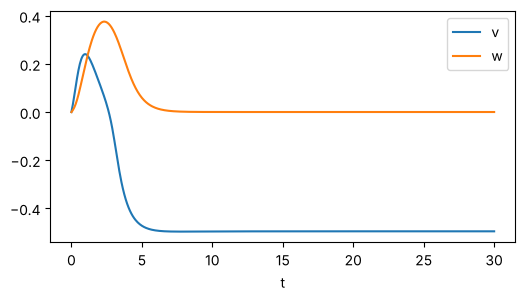

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(tr.t, tr["v"], label="v")
ax.plot(tr.t, tr["w"], label="w")
ax.set_xlabel("t"); ax.legend();

## Change parameters, initial conditions and numerics

`m.set` takes parameters, variables (initial conditions) and any `@` option from the .ode
syntax in one call. `run(**kw)` passes its keywords to `set` first.

200.0 0.025 rungekutta 8001


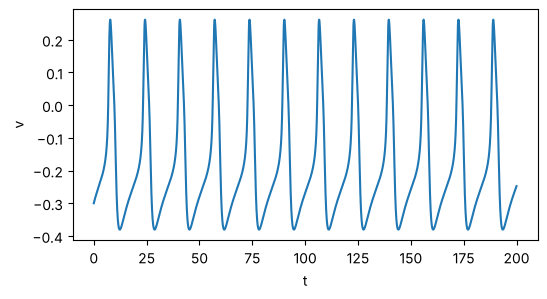

In [7]:
m.pars["iapp"] = 0.1
m.ics["v"] = -0.3
tr = m.run(total=200, dt=0.025, meth="rk4")
print(m.numerics["total"], m.numerics["dt"], m.numerics["meth"], len(tr))

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(tr.t, tr["v"])
ax.set_xlabel("t"); ax.set_ylabel("v");

## Continue from where the last run stopped

In [8]:
tr_next = m.run_last(total=50)       # Initialconds > Last
m.last_point()

{'V': -0.23687419295310974, 'W': 0.007166446652263403}

## Parameter sweeps

iapp restored to 0.1


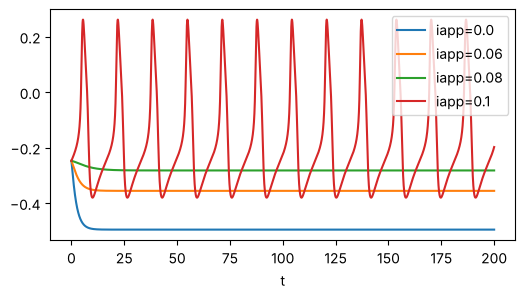

In [9]:
runs = m.sweep("iapp", [0.0, 0.06, 0.08, 0.1], total=200)
fig, ax = plt.subplots(figsize=(6, 3))
for iapp, r in zip([0.0, 0.06, 0.08, 0.1], runs):
    ax.plot(r.t, r["v"], label=f"iapp={iapp}")
ax.legend(); ax.set_xlabel("t");
print("iapp restored to", m.pars["iapp"])

## Data as pandas

In [10]:
m.data.to_pandas().head()

,t,V,W,CUR,ICA,IK,RATE
0,0.000,-0.247624,0.006473,0.1,-0.050374,0.005856,0.333
1,0.025,-0.247165,0.006499,0.1,-0.050651,0.005886,0.333
2,0.050,-0.246706,0.006526,0.1,-0.050931,0.005916,0.333
3,0.075,-0.246247,0.006553,0.1,-0.051212,0.005947,0.333
4,0.100,-0.245787,0.006580,0.1,-0.051495,0.005977,0.333


## Models from a string

Several models can be open at once; each runs in its own copy of the XPP library.

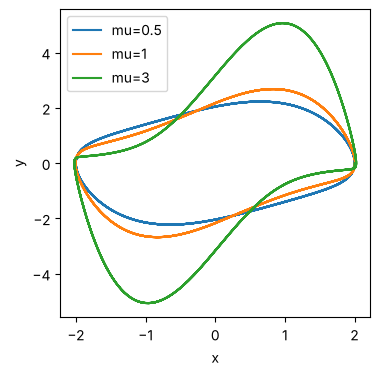

In [11]:
vdp = pyxpp.load(text='''
x'=y
y'=-x+mu*(1-x^2)*y
par mu=1
init x=2,y=0
@ total=40,dt=0.01
done
''')
fig, ax = plt.subplots(figsize=(4, 4))
for mu in [0.5, 1, 3]:
    vdp.pars["mu"] = mu
    t = vdp.run()
    ax.plot(t["x"], t["y"], label=f"mu={mu}")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend();

XPP's own messages:

In [12]:
print(m.log[-500:])

gca=1 phi=1.15 iapp=.080918 
MINF(V)=.5*(1+TANH((V-V1)/V2))  
NINF(V)=.5*(1+TANH((V-V3)/V4))  
LAMN(V)= PHI*COSH((V-V3)/(2*V4))  
ICA=GCA*MINF(V)*(V-1)  
0:dV/dt=  (IAPP+GL*(VL-V)+GK*W*(VK-V)-ICA)  
1:dW/dt= (LAMN(V)*(NINF(V)-W))  
cur=iapp  
ica=ica  
ik=gk*w*(v-vk)  
rate=phi  
 All formulas are valid!!
 nvar=2 naux=4 nfix=1 nmark=0 NEQ=6 NODE=7 
ICA is a duplicate name
Used 18 constants and 126 symbols 
XPPAUT 8.0 Copyright (C) 2002-now  Bard Ermentrout 
TrueColor visual:  no colormap needed

